<a href="https://colab.research.google.com/github/winwinjong-gif/Machin-Learning-report/blob/main/week5/DL_classification_image.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [49]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import tensorflow as tf
from sklearn import datasets, metrics
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
digits = datasets.load_digits()

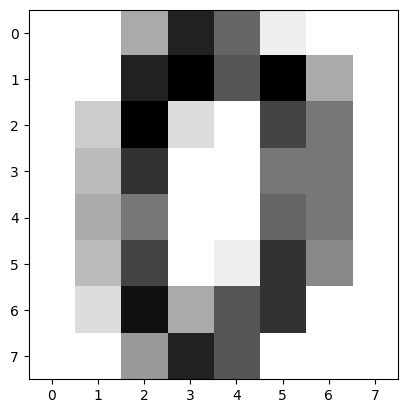

In [50]:
plt.imshow(
    digits.images[0],
    cmap=plt.cm.gray_r,
    interpolation='nearest'
)

In [51]:
n_samples = len(digits.images)
data = digits.images.reshape((n_samples, -1))
data

array([[ 0.,  0.,  5., ...,  0.,  0.,  0.],
       [ 0.,  0.,  0., ..., 10.,  0.,  0.],
       [ 0.,  0.,  0., ..., 16.,  9.,  0.],
       ...,
       [ 0.,  0.,  1., ...,  6.,  0.,  0.],
       [ 0.,  0.,  2., ..., 12.,  0.,  0.],
       [ 0.,  0., 10., ..., 12.,  1.,  0.]])

In [52]:
X = digits.data
y = digits.target

# 정답을 원핫 인코딩
y = pd.get_dummies(y).values

In [53]:
#입력과 출력의 개수 확인

print("입력 개수:", X.shape[1])
print("출력 개수:", y.shape[1])

입력 개수: 64
출력 개수: 10


In [54]:
X_train, X_test, y_train, y_test = train_test_split(
    X,y , test_size=0.2
)

In [55]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [56]:
model = tf.keras.Sequential()
model.add(tf.keras.layers.Dense(32, activation="relu", input_shape=(64,)))
model.add(tf.keras.layers.Dense(16, activation="relu"))
model.add(tf.keras.layers.Dense(10, activation="softmax"))

model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [57]:
model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_12 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 10)             │           170 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,778 (10.85 KB)

 Trainable params: 2,778 (10.85 KB)

 Non-trainable params: 0 (0.00 B)

In [58]:
history = model.fit(X_train, y_train, epochs=100, batch_size=32, validation_split=0.2, verbose=1)

Epoch 1/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.1932 - loss: 2.2534 - val_accuracy: 0.2951 - val_loss: 2.0178
Epoch 2/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4343 - loss: 1.7908 - val_accuracy: 0.5417 - val_loss: 1.6482
Epoch 3/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6536 - loss: 1.3788 - val_accuracy: 0.6701 - val_loss: 1.2685
Epoch 4/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7607 - loss: 1.0039 - val_accuracy: 0.7743 - val_loss: 0.9355
Epoch 5/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8529 - loss: 0.7154 - val_accuracy: 0.8403 - val_loss: 0.6846
Epoch 6/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8964 - loss: 0.5071 - val_accuracy: 0.8576 - val_loss: 0.5260
Epoch 7/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9199 - loss: 0.3744 - val_accuracy: 0.8785 - val_loss: 0.4175
Epoch 8/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9312 - loss: 0.2879 - val_accuracy: 0.8854 - v

In [59]:
y_prob = model.predict(X_test)

y_pred = np.argmax(y_prob, axis=1)

12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 


In [60]:
# 10. 성능 평가

y_true = np.argmax(y_test, axis=1)
accuracy = accuracy_score(y_true, y_pred)
print("\nAccuracy =", accuracy)
print("\nConfusion Matrix")
print(confusion_matrix(y_true, y_pred))
print("\nClassification Report")
print(classification_report(y_true, y_pred))


Accuracy = 0.9611111111111111

Confusion Matrix
[[45  0  0  0  0  0  0  0  0  0]
 [ 0 25  0  0  0  0  0  0  0  0]
 [ 0  0 30  2  0  0  0  0  0  0]
 [ 0  0  1 33  0  2  0  1  1  0]
 [ 0  0  0  0 46  0  0  2  0  0]
 [ 0  0  0  1  0 37  0  0  1  1]
 [ 0  0  0  0  0  0 38  0  0  0]
 [ 0  0  0  0  0  0  0 33  0  0]
 [ 0  0  0  0  0  0  0  0 22  0]
 [ 0  0  0  0  0  1  0  1  0 37]]

Classification Report
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        45
           1       1.00      1.00      1.00        25
           2       0.97      0.94      0.95        32
           3       0.92      0.87      0.89        38
           4       1.00      0.96      0.98        48
           5       0.93      0.93      0.93        40
           6       1.00      1.00      1.00        38
           7       0.89      1.00      0.94        33
           8       0.92      1.00      0.96        22
           9       0.97      0.95      0.96        39

 